# A pure interest-rate shock

No TFP shock, no demand shock, no planner. Cut the nominal rate below $\rho$ for a few
periods, put it back, and watch what happens. The model is `new_fixed_planner.ipynb`'s,
unchanged.

The question this is built to answer: **does a rate cut today move output in future
periods, and through what?**

In this model the rate reaches the price level through one channel only — the financing
cost $\beta^{\tau_i}$ that each firm carries over its production window. A firm delivering
at $t$ borrowed over $[t-\tau_i+1,\,t]$, so a cut at $t=0$ is inside the window of every
firm delivering at $t=0,1,\dots,\tau_i$. Prices therefore stay depressed for about $\tau$
periods and then recover. That recovery is *positive expected inflation*, which sits in the
Euler equation as $\pi_{t+1}$ and holds the real rate below $\rho$ for the whole window.

That is the mechanism, and whether it survives into consumption depends on one
specification choice, which is what section 5 is about.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration — identical to `new_fixed_planner.ipynb`

In [2]:
INVENTORY_TO_COGS_SCALING = 36.5
NOMINAL_INTEREST_RATE = 0.01
sigma = 5
gamma = 2.0
eta = 2.0
chi = 1.0
PHI_YA = (1 + eta) / (gamma + eta)

beta = 1 / (1.0 + NOMINAL_INTEREST_RATE)
beta1 = 1 / (1.0 + NOMINAL_INTEREST_RATE * np.exp(30 / (INVENTORY_TO_COGS_SCALING * 0.9)))
beta_hh = beta
rho = 1 / beta_hh - 1
T = 40

print(f'gamma={gamma}, eta={eta}, phi_ya={PHI_YA}, rho={100*rho:.2f}%')

gamma=2.0, eta=2.0, phi_ya=0.75, rho=1.00%


In [3]:
data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N)
pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

tvals = tau.astype(int).to_numpy()
NFIRMS = len(tvals)
Z_PHYS = c * (tvals + np.array(N))

print(f'c = {c:.7f}   firms = {NFIRMS}   tau in [{tvals.min()}, {tvals.max()}], '
      f'mean {tau.mean():.3f}')
print(f'firms by tau: {np.bincount(tvals)}')

TVALS_TTB = tvals                            # time to build: the calibrated tau distribution
TVALS_NTB = np.zeros_like(tvals)             # no time to build: every firm delivers on the spot

print(f'TTB: tau in [{TVALS_TTB.min()}, {TVALS_TTB.max()}]    '
      f'NTB: tau == 0 for all {NFIRMS} firms')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_58317/2108889166.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


c = 0.9018018   firms = 269   tau in [0, 13], mean 2.888
firms by tau: [ 1 31 97 66 48 18  1  2  0  2  1  1  0  1]
TTB: tau in [0, 13]    NTB: tau == 0 for all 269 firms


## 2. The model

Identical to `new_fixed_planner.ipynb`, with both specification switches carried over:

* `rate_matrix` keeps its history — row $t$ holds $i_{t-k}$, so the rate's influence runs to
  $t+\tau_i-1$, not to $t=L$;
* the price index is the CES one, $P=1/\tilde A$, so $\pi_t=-(a_t-a_{t-1})$;
* `euler_on` selects whether the household's Euler equation applies to measured consumption
  $y=c+d$ or to physical consumption $c$ — see section 4.

With no TFP shock, physical productivity never moves, so $a^{\text{phys}}=0$ and the
efficient level of consumption is the steady state. Any movement in $c$ is a deviation from
efficiency.

**Equilibrium labour.** The new object reported below is aggregate labour, built firm by
firm rather than from the aggregate resource constraint. CES demand gives
$y_{i,t}/Y_t=(p_{i,t}/P_t)^{-\sigma}$ with $p_i=\text{markup}/\widetilde{a}_{i}$ and
$P=\text{markup}/\tilde A$, so $y_{i,t}=Y_t(\widetilde a_{i,t}/\tilde A_t)^{\sigma}$, and
firm $i$ converts one unit of labour into $z_i=c\,(\tau_i+N_i)$ units of its own good.
Labour is therefore

$$L=\sum_i \frac{y_i}{z_i},$$

**with the start time held fixed**: a firm with lag $\tau_i$ that *starts* at $s$ *delivers*
at $s+\tau_i$, so the labour booked to date $s$ is $\sum_i n_{i,\,s+\tau_i}$, not
$\sum_i n_{i,s}$. Because $\sum_i y_i/z_i$ keeps each firm's relative
price, it is not $c-a^{\text{phys}}$: the gap between them is exactly the relative-price
dispersion the rate creates across $\tau$ cohorts.

**No time to build.** `tv=TVALS_NTB` sets $\tau_i=0$ for every firm. Nothing else changes —
same $z_i$, same $\sigma$, same household. With $\tau=0$ no firm carries a financing cost,
so $\tilde A$ is constant, $\pi\equiv 0$, there is no dispersion, and labour equals
consumption exactly. It is the frictionless benchmark every figure below is measured
against.

In [4]:
def rate_matrix(r, T=T):
    """irl[t, k] = the nominal rate that prevailed at date t - k."""
    r = np.asarray(r, float); L = len(r)
    idx = np.subtract.outer(np.arange(T), np.arange(T))
    return np.where((idx >= 0) & (idx < L), r[np.clip(idx, 0, L - 1)], rho)


def solve(r, T=T, euler_on='physical', tv=None):
    """Pure rate experiment: no TFP shock, no demand shock.

    `tv` is the time-to-build vector: TVALS_TTB is the calibrated one, TVALS_NTB is
    the same economy with the production lag switched off (tau_i = 0 everywhere, so
    no firm ever carries a financing cost and the rate reaches no price).
    """
    tv = TVALS_TTB if tv is None else np.asarray(tv, int)
    irl = rate_matrix(r, T)
    ce = np.ones((T, T + 1))
    ce[:, 1:] = np.cumprod(1.0 / (1.0 + irl), axis=1)
    disc = ce[:, tv]
    tprod = disc * Z_PHYS

    A_til = np.sum(tprod**(sigma - 1), axis=1)**(1 / (sigma - 1))     # measured TFP
    Z_t = np.sum(Z_PHYS**(sigma - 1))**(1 / (sigma - 1))              # physical TFP
    a_nat = np.log(A_til) - np.log(A_til)[-1]
    d = np.log(A_til) - np.log(Z_t); d = d - d[-1]
    a_phys = a_nat - d                                                # == 0 here
    pi = np.zeros(T); pi[1:] = -(a_nat[1:] - a_nat[:-1])              # P = 1 / Atil
    pi_fwd = np.r_[pi[1:], 0.0]

    ip = np.ones(T) * rho
    ip[:len(r)] = np.asarray(r, float)

    base = a_nat if euler_on == 'measured' else a_phys
    y_nat = PHI_YA * base
    dy = np.r_[y_nat[1:] - y_nat[:-1], 0.0]
    r_nat = rho + gamma * dy

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (ip[t] - pi_fwd[t] - r_nat[t])
    x = x[:T]

    if euler_on == 'measured':
        c_meas = x + PHI_YA * a_nat
        cc = c_meas - d
    else:
        cc = x + PHI_YA * a_phys
        c_meas = cc + d

    # ---- equilibrium labour, firm by firm --------------------------------------
    # CES demand gives y_i/Y = (p_i/P)^-sigma, and p_i = markup/tprod_i, P = markup/Atil,
    # so y_i = Y (tprod_i/Atil)^sigma.  Firm i turns one unit of labour into Z_PHYS_i
    # units of its own good, so its labour is n_i = y_i / z_i with z_i = Z_PHYS_i.
    Y = np.exp(cc)                                                    # CES basket, ss = 1
    n_firm = (tprod / A_til[:, None])**sigma * Y[:, None] / Z_PHYS    # n[t, i], t = DELIVERY

    # HOLD THE START TIME FIXED: a firm with lag tau_i that starts at s delivers at
    # s + tau_i, so the labour booked to start-date s is sum_i n_i[s + tau_i, i].
    idx = np.clip(np.arange(T)[:, None] + tv[None, :], 0, T - 1)
    L_start = np.take_along_axis(n_firm, idx, axis=0).sum(axis=1)
    L_del = n_firm.sum(axis=1)                                        # delivery-indexed (unused)

    lab = np.log(L_start) - np.log(L_start[-1])
    lab_del = np.log(L_del) - np.log(L_del[-1])

    return dict(i=ip, logP=-a_nat, pi=pi, a_nat=a_nat, d=d, a_phys=a_phys,
                x=x, c=cc, c_meas=c_meas, n=cc - a_phys, r_real=ip - pi_fwd,
                L=L_start, lab=lab, lab_del=lab_del, n_firm=n_firm, tv=tv)


def path(cut_bp, length=1):
    """Rate path: cut `cut_bp` basis points below rho for `length` periods, then rho."""
    return np.r_[np.full(length, rho - cut_bp / 10000.0), np.full(20, rho)]

print('model ready.  a_phys == 0 by construction here, so c_eff == 0:')
print(f'   max |a_phys| = {np.max(np.abs(solve(path(50))["a_phys"])):.2e}')
print('no time to build collapses to the frictionless benchmark:')
_ntb = solve(path(50), tv=TVALS_NTB)
print(f'   max |pi| = {np.max(np.abs(_ntb["pi"])):.2e},  '
      f'max |labour - consumption| = {np.max(np.abs(_ntb["lab"] - _ntb["c"])):.2e}')

model ready.  a_phys == 0 by construction here, so c_eff == 0:
   max |a_phys| = 0.00e+00
no time to build collapses to the frictionless benchmark:
   max |pi| = 0.00e+00,  max |labour - consumption| = 3.91e-16


## 3. A 50bp cut for one period

The transmission chain, period by period. Read it top to bottom: the rate falls, measured
TFP rises and stays up for about $\tau$ periods, the unwinding of that is positive
inflation, and that inflation is what holds the real rate below $\rho$. The last three rows
are what the cut does to quantities — consumption, labour with the start time held fixed,
and the same labour without time to build.

In [5]:
H = 12
s  = solve(path(50), euler_on='physical', tv=TVALS_TTB)
sn = solve(path(50), euler_on='physical', tv=TVALS_NTB)
print('50bp cut at t = 0 only (i_0 = 0.50% against rho = 1.00%).  Per cent.\n')
rows = [('nominal rate  i_t',            s['i']),
        ('real rate  i_t - pi_{t+1}',    s['r_real']),
        ('inflation  pi_t',              s['pi']),
        ('measured TFP  a_t',            s['a_nat']),
        ('discount content  d_t',        s['d']),
        ('physical TFP  a^phys_t',       s['a_phys']),
        ('CONSUMPTION  c_t',             s['c']),
        ('LABOUR  l_t  (start-indexed)', s['lab']),
        ('  labour, NO time to build',   sn['lab'])]
print(f'   {"":<30}' + ''.join(f'{t:>9}' for t in range(H)))
print('   ' + '-' * 138)
for lab_, v in rows:
    print(f'   {lab_:<30}' + ''.join(f'{100*v[t]:>9.4f}' for t in range(H)))

n_live = int(np.sum(np.abs(s['a_nat']) > 1e-6))
print(f'\n   periods with measured TFP moved: {n_live}   (max tau = {tvals.max()})')
print(f'   consumption is raised in {int(np.sum(s["c"] > 1e-9))} periods, '
      f'peak {100*s["c"].max():.4f}% at t = {int(np.argmax(s["c"]))}')
print(f'   half-life of the consumption response: '
      f'{int(np.argmax(s["c"] < 0.5 * s["c"].max()))} periods')
print(f'   start-indexed labour: trough {100*s["lab"].min():.4f}% at t = '
      f'{int(np.argmin(s["lab"]))}, cumulative {100*np.sum(s["lab"]):.4f} pp-periods')
print(f'   without time to build labour == consumption exactly '
      f'(max gap {np.max(np.abs(sn["lab"] - sn["c"])):.2e}) and dies after one period.')

50bp cut at t = 0 only (i_0 = 0.50% against rho = 1.00%).  Per cent.

                                         0        1        2        3        4        5        6        7        8        9       10       11
   ------------------------------------------------------------------------------------------------------------------------------------------
   nominal rate  i_t                0.5000   1.0000   1.0000   1.0000   1.0000   1.0000   1.0000   1.0000   1.0000   1.0000   1.0000   1.0000
   real rate  i_t - pi_{t+1}        0.4423   0.8208   0.8762   0.9108   0.9673   0.9983   0.9971   1.0000   0.9969   0.9985   0.9984   1.0000
   inflation  pi_t                  0.0000   0.0577   0.1792   0.1238   0.0892   0.0327   0.0017   0.0029  -0.0000   0.0031   0.0015   0.0016
   measured TFP  a_t                0.4946   0.4369   0.2577   0.1339   0.0448   0.0120   0.0104   0.0074   0.0074   0.0043   0.0029   0.0013
   discount content  d_t            0.4946   0.4369   0.2577   0.1339   0.0448

wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_rate_shock_sizes.png


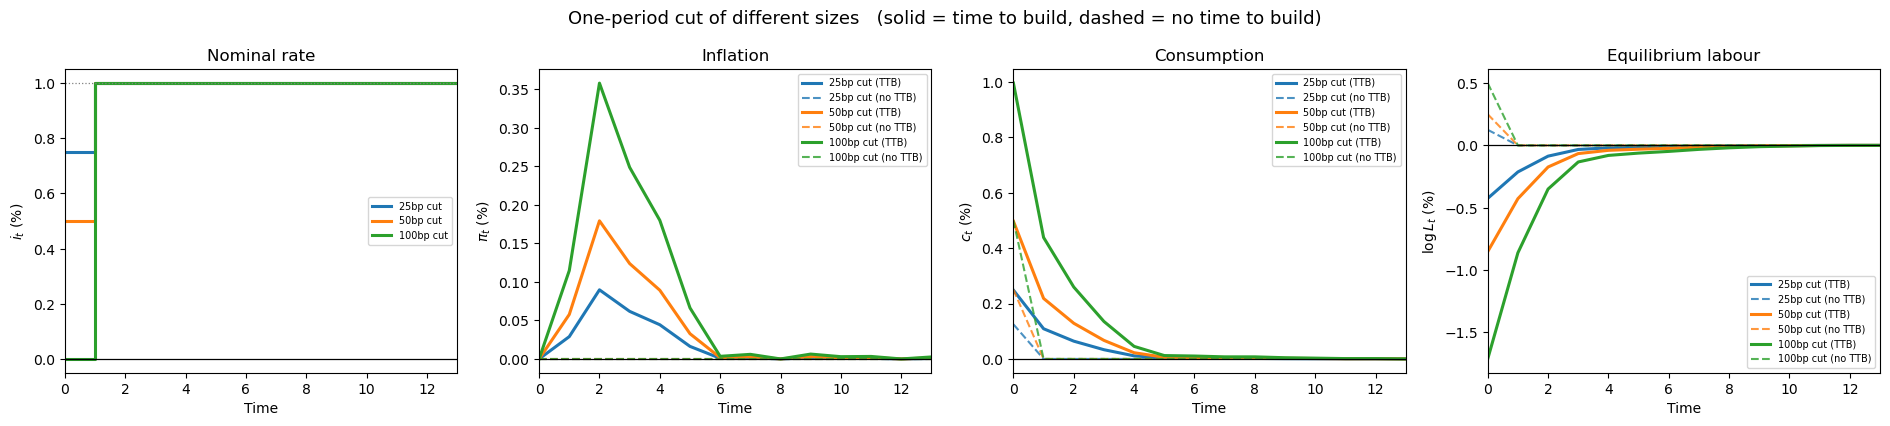

In [6]:
PANELS = [('Nominal rate',       'i',   r'$i_t$ (%)'),
          ('Inflation',          'pi',  r'$\pi_t$ (%)'),
          ('Consumption',        'c',   r'$c_t$ (%)'),
          ('Equilibrium labour', 'lab', r'$\log L_t$ (%)')]


def rate_figure(paths, labels, fname, suptitle, euler_on='physical', H=14,
                compare_ntb=True):
    """Four panels: rate, inflation, consumption, equilibrium labour.

    Solid = time to build (calibrated tau), dashed = the same cut with no time to build.
    """
    fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
    t = np.arange(H)
    for j, (rr, lb) in enumerate(zip(paths, labels)):
        col = f'C{j}'
        st = solve(rr, euler_on=euler_on, tv=TVALS_TTB)
        sn = solve(rr, euler_on=euler_on, tv=TVALS_NTB)
        for ax, (ttl, key, yl) in zip(axes, PANELS):
            if key == 'i':
                ax.step(t, 100 * st[key][:H], where='post', lw=2.2, color=col, label=lb)
                continue
            ax.plot(t, 100 * st[key][:H], lw=2.2, color=col, label=f'{lb} (TTB)')
            if compare_ntb:
                ax.plot(t, 100 * sn[key][:H], lw=1.5, ls='--', color=col, alpha=0.8,
                        label=f'{lb} (no TTB)')
    for ax, (ttl, key, yl) in zip(axes, PANELS):
        ax.axhline(0, color='k', lw=0.9); ax.set_xlim(0, H - 1)
        ax.set_xlabel('Time'); ax.set_ylabel(yl); ax.set_title(ttl)
        ax.legend(fontsize=7)
    axes[0].axhline(100 * rho, color='grey', lw=0.9, ls=':')
    fig.suptitle(suptitle + '   (solid = time to build, dashed = no time to build)',
                 fontsize=13)
    fig.tight_layout()
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    print(f'wrote {os.path.abspath(fname)}')
    plt.show(); plt.close(fig)


rate_figure([path(25), path(50), path(100)],
            ['25bp cut', '50bp cut', '100bp cut'],
            '../semi_endo_rate_shock_sizes.png',
            'One-period cut of different sizes')

### 3b. How much is the direct Euler channel, and how much is the price change?

Two things move quantities when the rate falls. The **direct** one is the Euler equation
itself: $i_t$ below $\rho$ raises $c_t$ whether or not any price responds. The **indirect**
one needs time to build: the cut lowers the financing cost inside every open production
window, the price level falls and then recovers, and that recovery is expected inflation
sitting in the same Euler equation as $\pi_{t+1}$.

With $a^{\text{phys}}=0$ the natural rate is just $\rho$, so the Euler equation solves
forward and the two separate **exactly**:

$$c_t=\underbrace{\frac1\gamma\sum_{s\ge t}(\rho-i_s)}_{\text{direct rate term}}
      +\underbrace{\frac1\gamma\sum_{s\ge t}\pi_{s+1}}_{\text{price / inflation term}}$$

The first term is precisely the no-time-to-build path — it is nonzero only while the cut is
on. Everything after the cut ends is the second term. Labour is split the same way to first
order, with two extra pieces that act on the cohort's relative price directly: its own
financing cost, and the aggregate price index it is measured against.


wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_rate_shock_decomposition.png


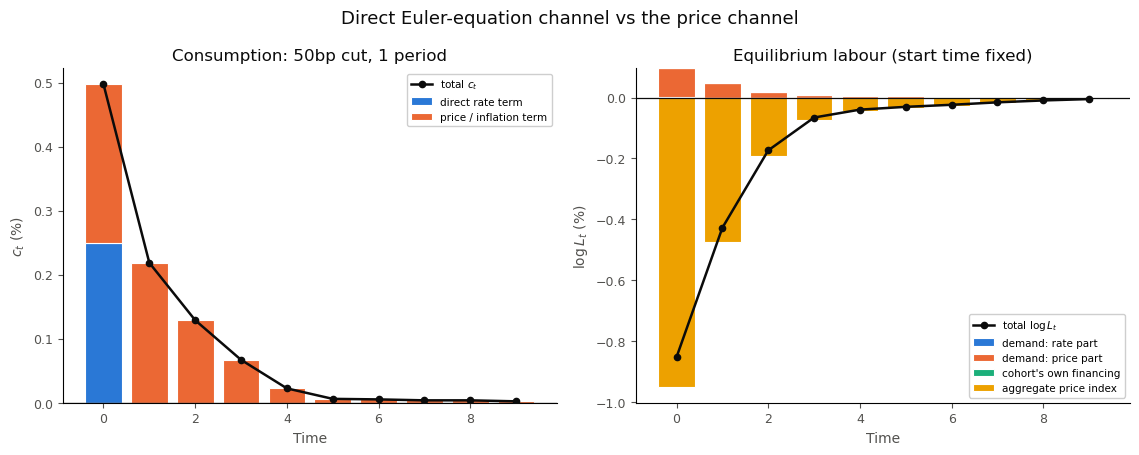


CONSUMPTION, 50bp one-period cut (%)

                                     0        1        2        3        4        5        6        7
   --------------------------------------------------------------------------------------------------
   direct rate term             0.2500   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000   0.0000
   price / inflation term       0.2473   0.2185   0.1288   0.0670   0.0224   0.0060   0.0052   0.0037
   sum                          0.4973   0.2185   0.1288   0.0670   0.0224   0.0060   0.0052   0.0037
   actual c_t                   0.4973   0.2185   0.1288   0.0670   0.0224   0.0060   0.0052   0.0037

   max |(rate + price) - c| = 0.00e+00   <-- EXACT
   direct term == no-time-to-build consumption: max err 0.00e+00

EQUILIBRIUM LABOUR, start time fixed (%)

                                     0        1        2        3        4        5        6        7
   ------------------------------------------------------------------------------------

In [7]:
CAT = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']   # validated categorical slots 1-4
INK, MUTED = '#0b0b0b', '#52514e'


def decompose(r, tv=TVALS_TTB):
    """Split the response into the DIRECT RATE term and the PRICE term.

    a_phys == 0 here, so the natural rate is rho and the Euler equation solves
    forward exactly:
        c_t = (1/gamma) sum_{s>=t} (rho - i_s)  +  (1/gamma) sum_{s>=t} pi_{s+1}
               \_ direct rate term _/             \_ price / inflation term _/
    The first term is what the cut does with NO time to build; the second is
    everything the production lag adds.  Labour is decomposed to first order
    around the steady state into the same two demand pieces plus the two
    relative-price pieces that act on the cohort directly.
    """
    s = solve(r, tv=tv)
    pi_fwd = np.r_[s['pi'][1:], 0.0]
    c_rate  = np.array([np.sum(rho - s['i'][t:]) / gamma for t in range(T)])
    c_price = np.array([np.sum(pi_fwd[t:]) / gamma       for t in range(T)])

    irl = rate_matrix(r, T); ce = np.ones((T, T + 1))
    ce[:, 1:] = np.cumprod(1 / (1 + irl), 1)
    disc = ce[:, tv]
    w = solve(np.array([rho]), tv=tv)['n_firm'][-1]
    w = w / w.sum()
    idx = np.clip(np.arange(T)[:, None] + tv[None, :], 0, T - 1)
    take = lambda v: np.take_along_axis(np.tile(v[:, None], (1, NFIRMS)), idx, 0)
    l_rate  = (take(c_rate) * w).sum(1)
    l_price = (take(c_price) * w).sum(1)
    l_own   = sigma * (np.take_along_axis(np.log(disc) - np.log(disc[-1]), idx, 0) * w).sum(1)
    l_agg   = -sigma * (take(s['a_nat']) * w).sum(1)
    return s, (c_rate, c_price), (l_rate, l_price, l_own, l_agg)


def _stack(ax, t, comps, labels):
    """Contribution bars: positives stack up, negatives stack down."""
    pos = np.zeros(len(t)); neg = np.zeros(len(t))
    for v, col, lb in zip(comps, CAT, labels):
        vp, vn = np.clip(v, 0, None), np.clip(v, None, 0)
        ax.bar(t, vp, bottom=pos, color=col, label=lb, width=.8, lw=.8, edgecolor='white')
        ax.bar(t, vn, bottom=neg, color=col, width=.8, lw=.8, edgecolor='white')
        pos += vp; neg += vn


def decomposition_figure(fname, bp=50, H=10):
    s, (cr, cp), (lr, lp, lo, la) = decompose(path(bp))
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
    t = np.arange(H)

    _stack(axes[0], t, [100*cr[:H], 100*cp[:H]],
           ['direct rate term', 'price / inflation term'])
    axes[0].plot(t, 100*s['c'][:H], color=INK, lw=1.8, marker='o', ms=4.5,
                 label='total $c_t$', zorder=5)
    axes[0].set_title(f'Consumption: {bp}bp cut, 1 period', color=INK)
    axes[0].set_ylabel('$c_t$ (%)', color=MUTED)

    _stack(axes[1], t, [100*lr[:H], 100*lp[:H], 100*lo[:H], 100*la[:H]],
           ['demand: rate part', 'demand: price part',
            "cohort's own financing", 'aggregate price index'])
    axes[1].plot(t, 100*s['lab'][:H], color=INK, lw=1.8, marker='o', ms=4.5,
                 label='total $\\log L_t$', zorder=5)
    axes[1].set_title('Equilibrium labour (start time fixed)', color=INK)
    axes[1].set_ylabel(r'$\log L_t$ (%)', color=MUTED)

    for ax in axes:
        ax.axhline(0, color=INK, lw=.9); ax.set_xlabel('Time', color=MUTED)
        ax.legend(fontsize=7.5, framealpha=.95)
        ax.tick_params(colors=MUTED, labelsize=9)
        for sp in ('top', 'right'):
            ax.spines[sp].set_visible(False)
    fig.suptitle('Direct Euler-equation channel vs the price channel', fontsize=13, color=INK)
    fig.tight_layout()
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    print(f'wrote {os.path.abspath(fname)}')
    plt.show(); plt.close(fig)


decomposition_figure('../semi_endo_rate_shock_decomposition.png')

# ---- the table (relief for the two low-contrast slots, and the exactness check) ----
s, (cr, cp), (lr, lp, lo, la) = decompose(path(50))
H = 8
print('\nCONSUMPTION, 50bp one-period cut (%)\n')
print(f'   {"":<26}' + ''.join(f'{t:>9}' for t in range(H)))
print('   ' + '-' * (26 + 9 * H))
for nm, v in [('direct rate term', cr), ('price / inflation term', cp),
              ('sum', cr + cp), ('actual c_t', s['c'])]:
    print(f'   {nm:<26}' + ''.join(f'{100*v[t]:>9.4f}' for t in range(H)))
print(f'\n   max |(rate + price) - c| = {np.max(np.abs(cr + cp - s["c"])):.2e}   <-- EXACT')
print(f'   direct term == no-time-to-build consumption: max err '
      f'{np.max(np.abs(cr - solve(path(50), tv=TVALS_NTB)["c"])):.2e}')

print('\nEQUILIBRIUM LABOUR, start time fixed (%)\n')
print(f'   {"":<26}' + ''.join(f'{t:>9}' for t in range(H)))
print('   ' + '-' * (26 + 9 * H))
for nm, v in [('demand: rate part', lr), ('demand: price part', lp),
              ("cohort's own financing", lo), ('aggregate price index', la),
              ('sum', lr + lp + lo + la), ('actual log L_t', s['lab'])]:
    print(f'   {nm:<26}' + ''.join(f'{100*v[t]:>9.4f}' for t in range(H)))
print(f'\n   max |sum - log L| over t < 14 = '
      f'{np.max(np.abs((lr + lp + lo + la - s["lab"])[:14])):.2e}  (first order, not exact)')
print("\n   note the cohort's own financing term is IDENTICALLY ZERO: a cohort starting")
print('   at s is charged rates over [s+1, s+tau], so a cut at s never touches it.')

wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_rate_shock_lengths.png


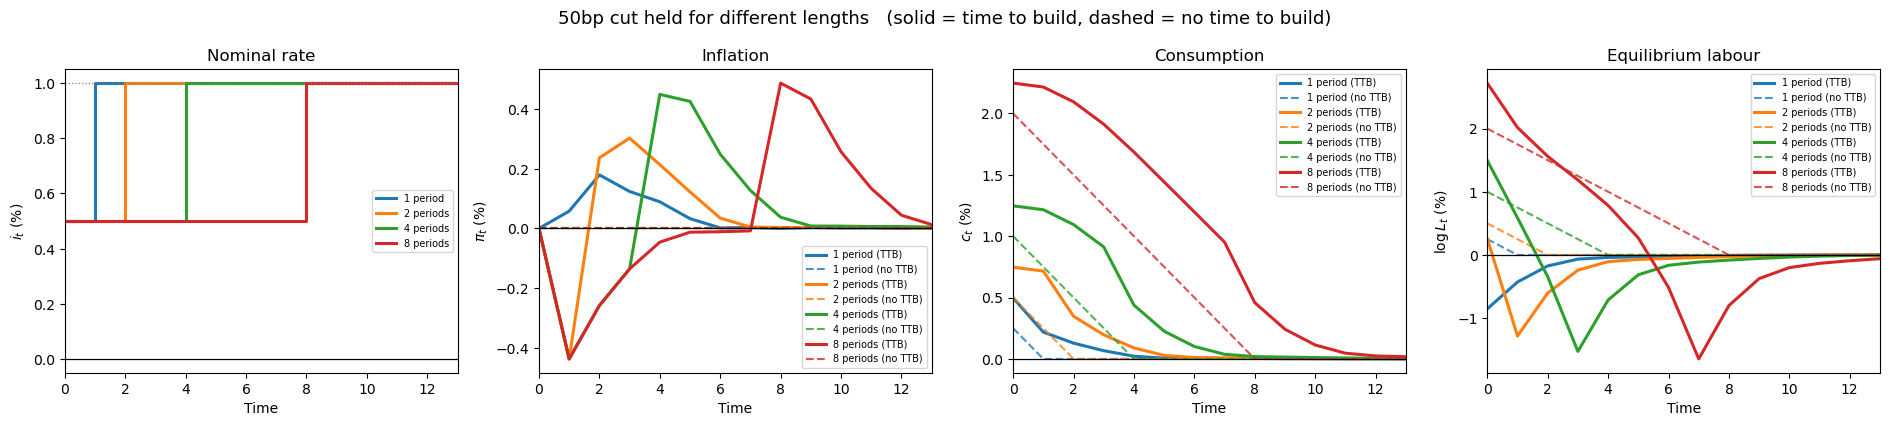

In [8]:
rate_figure([path(50, 1), path(50, 2), path(50, 4), path(50, 8)],
            ['1 period', '2 periods', '4 periods', '8 periods'],
            '../semi_endo_rate_shock_lengths.png',
            '50bp cut held for different lengths')

## 4. A lot of shocks, with and without time to build

The sweep: eight cut sizes crossed with six lengths, each solved twice — once with the
calibrated $\tau$ distribution and once with $\tau_i=0$ everywhere. What the pair isolates
is the entire contribution of the production lag, since the two economies are identical in
every other respect.

The comparison is sharpest in labour. Without time to build, $L_t=C_t$ period by period:
the cut raises consumption while it is on and nothing else happens. With time to build,
labour held at its *start* date moves the opposite way from consumption. A cut at $t$ sits
in the financing window $[t-\tau_i+1,\,t]$ of the firms that are already mid-production, so
those are the firms whose prices fall and whose demand rises. A firm *starting* at $t$
delivers at $t+\tau_i$ over the window $[t+1,\,t+\tau_i]$, which never contains the cut —
it gets none of the discount, is dear relative to a cheapened aggregate, and sheds demand.


In [9]:
CUTS    = np.array([10, 25, 50, 75, 100, 150, 200, 300])   # basis points below rho
LENGTHS = np.array([1, 2, 3, 4, 6, 8])                     # periods the cut is held

SHOCKS = [(bp, ln) for bp in CUTS for ln in LENGTHS]
RES = {}
for bp, ln in SHOCKS:
    rr = path(bp, ln)
    RES[(bp, ln, 'ttb')] = solve(rr, euler_on='physical', tv=TVALS_TTB)
    RES[(bp, ln, 'ntb')] = solve(rr, euler_on='physical', tv=TVALS_NTB)

print(f'{len(SHOCKS)} rate paths solved twice each '
      f'({len(CUTS)} sizes x {len(LENGTHS)} lengths, time to build and not).')
print(f'   cuts    (bp) : {list(CUTS)}')
print(f'   lengths (per): {list(LENGTHS)}')
print(f'   total easing ranges over {CUTS.min()*LENGTHS.min()} to '
      f'{CUTS.max()*LENGTHS.max()} bp-periods')

48 rate paths solved twice each (8 sizes x 6 lengths, time to build and not).
   cuts    (bp) : [10, 25, 50, 75, 100, 150, 200, 300]
   lengths (per): [1, 2, 3, 4, 6, 8]
   total easing ranges over 10 to 2400 bp-periods


wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_rate_shock_grid_ttb_vs_ntb.png


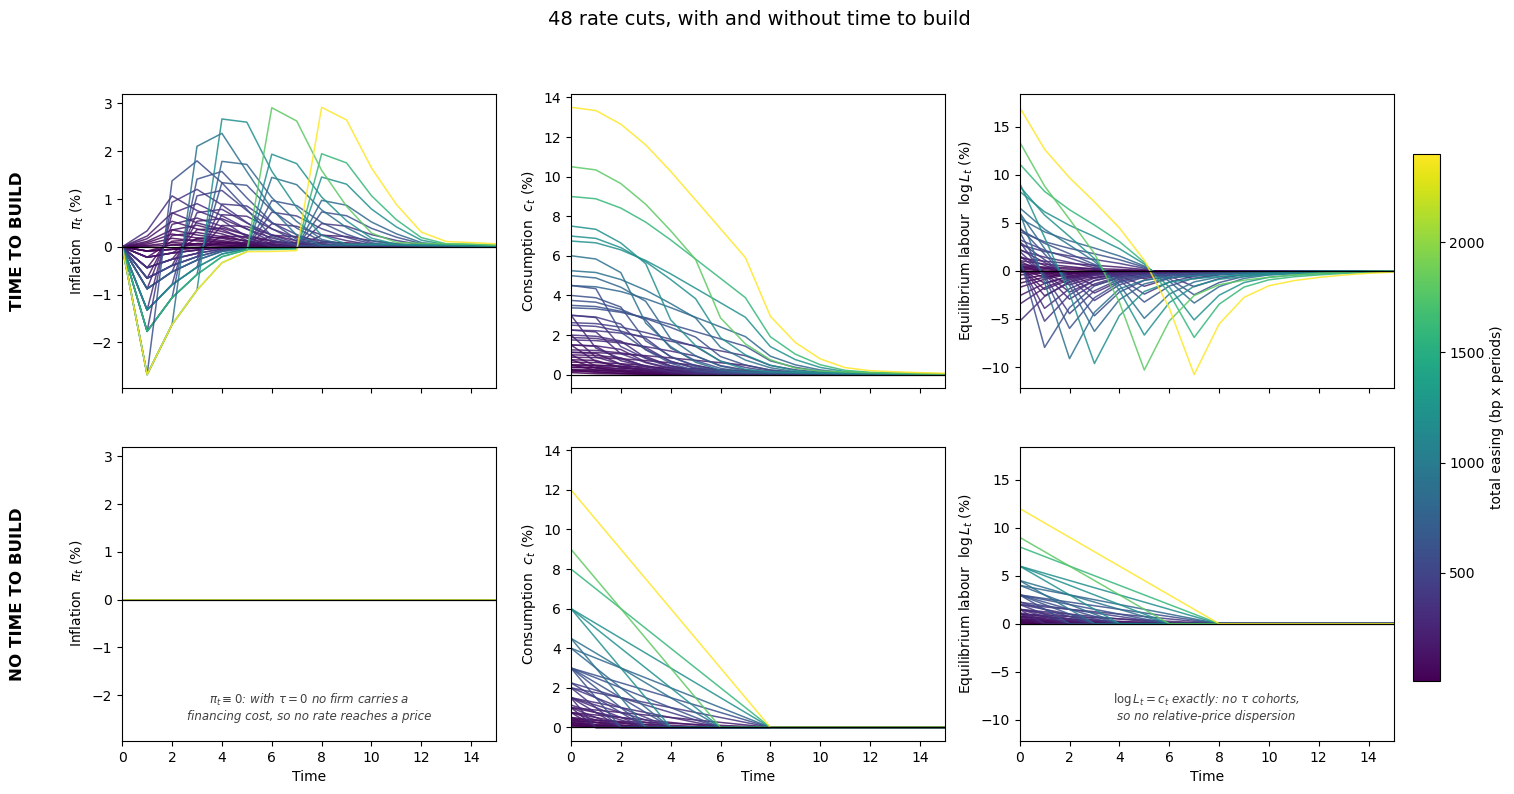

In [10]:
def shock_grid_figure(fname, H=16):
    """Every shock in the sweep, time to build on top, no time to build below."""
    keys = [('pi', r'Inflation  $\pi_t$ (%)'),
            ('c',  r'Consumption  $c_t$ (%)'),
            ('lab', r'Equilibrium labour  $\log L_t$ (%)')]
    easing = np.array([bp * ln for bp, ln in SHOCKS], float)
    norm = plt.Normalize(easing.min(), easing.max())
    cmap = plt.cm.viridis
    fig, axes = plt.subplots(2, 3, figsize=(17, 8.4), sharex=True)
    t = np.arange(H)
    for row, reg, rlab in [(0, 'ttb', 'TIME TO BUILD'),
                           (1, 'ntb', 'NO TIME TO BUILD')]:
        for col, (key, yl) in enumerate(keys):
            ax = axes[row, col]
            for (bp, ln) in SHOCKS:
                ax.plot(t, 100 * RES[(bp, ln, reg)][key][:H],
                        lw=1.1, alpha=0.85, color=cmap(norm(bp * ln)))
            ax.axhline(0, color='k', lw=0.9)
            ax.set_xlim(0, H - 1); ax.set_ylabel(yl)
            if row == 1:
                ax.set_xlabel('Time')
            if col == 0:
                ax.text(-0.28, 0.5, rlab, transform=ax.transAxes, rotation=90,
                        va='center', ha='center', fontsize=12, fontweight='bold')
            if reg == 'ntb' and key in ('pi', 'lab'):
                note = (r'$\pi_t \equiv 0$: with $\tau = 0$ no firm carries a'
                        '\nfinancing cost, so no rate reaches a price'
                        if key == 'pi' else
                        r'$\log L_t = c_t$ exactly: no $\tau$ cohorts,'
                        '\nso no relative-price dispersion')
                ax.text(0.5, 0.06, note, transform=ax.transAxes, ha='center',
                        va='bottom', fontsize=8.5, style='italic', color='0.25')
    for col in range(3):                       # common scale down each column
        lo = min(axes[r, col].get_ylim()[0] for r in (0, 1))
        hi = max(axes[r, col].get_ylim()[1] for r in (0, 1))
        for r in (0, 1):
            axes[r, col].set_ylim(lo, hi)
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap); sm.set_array([])
    cb = fig.colorbar(sm, ax=axes, fraction=0.02, pad=0.015)
    cb.set_label('total easing (bp x periods)')
    fig.suptitle(f'{len(SHOCKS)} rate cuts, with and without time to build', fontsize=14)
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    print(f'wrote {os.path.abspath(fname)}')
    plt.show(); plt.close(fig)


shock_grid_figure('../semi_endo_rate_shock_grid_ttb_vs_ntb.png')

In [11]:
def grid_table(stat, f, fmt='{:>9.4f}'):
    print(f'\n{stat}   (rows = cut in bp, cols = length in periods)\n')
    for reg, rlab in [('ttb', 'time to build'), ('ntb', 'no time to build')]:
        print(f'   {rlab:<18}' + ''.join(f'{ln:>9}' for ln in LENGTHS))
        print('   ' + '-' * (18 + 9 * len(LENGTHS)))
        for bp in CUTS:
            print(f'   {str(bp)+"bp":<18}'
                  + ''.join(fmt.format(f(RES[(bp, ln, reg)])) for ln in LENGTHS))
        print()


grid_table('CUMULATIVE CONSUMPTION  sum_t c_t (pp-periods)',
           lambda s: 100 * np.sum(s['c']))
grid_table('CUMULATIVE LABOUR  sum_t log L_t (pp-periods, start-indexed)',
           lambda s: 100 * np.sum(s['lab']))
grid_table('PERIODS WITH |c_t| > 1e-6', lambda s: int(np.sum(np.abs(s['c']) > 1e-8)),
           fmt='{:>9d}')

print('Read the three tables together:')
print('  * without time to build a cut of any size or length moves consumption only')
print('    while it is on -- the response ends with the cut, and labour moves with it')
print('    one for one, because tau = 0 leaves no relative-price dispersion.')
print('  * with time to build the same cut is still working ~max(tau) periods later,')
print('    and labour booked to the START date goes the OTHER way: the firms that begin')
print('    production when the cut lands never have it in their financing window, so')
print('    they are the expensive ones and lose demand.')


CUMULATIVE CONSUMPTION  sum_t c_t (pp-periods)   (rows = cut in bp, cols = length in periods)

   time to build             1        2        3        4        6        8
   ------------------------------------------------------------------------
   10bp                 0.1909   0.4319   0.7230   1.0640   1.8961   2.9283
   25bp                 0.4779   1.0811   1.8096   2.6632   4.7456   7.3282
   50bp                 0.9575   2.1667   3.6268   5.3373   9.5091  14.6814
   75bp                 1.4389   3.2568   5.4515   8.0222  14.2906  22.0603
   100bp                1.9222   4.3514   7.2839  10.7183  19.0906  29.4655
   150bp                2.8941   6.5542  10.9721  16.1444  28.7475  44.3569
   200bp                3.8734   8.7757  14.6921  21.6168  38.4826  59.3608
   300bp                5.8545  13.2758  22.2308  32.7064  58.2006  89.7294

   no time to build          1        2        3        4        6        8
   ----------------------------------------------------------------

wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_rate_shock_labour_timing.png


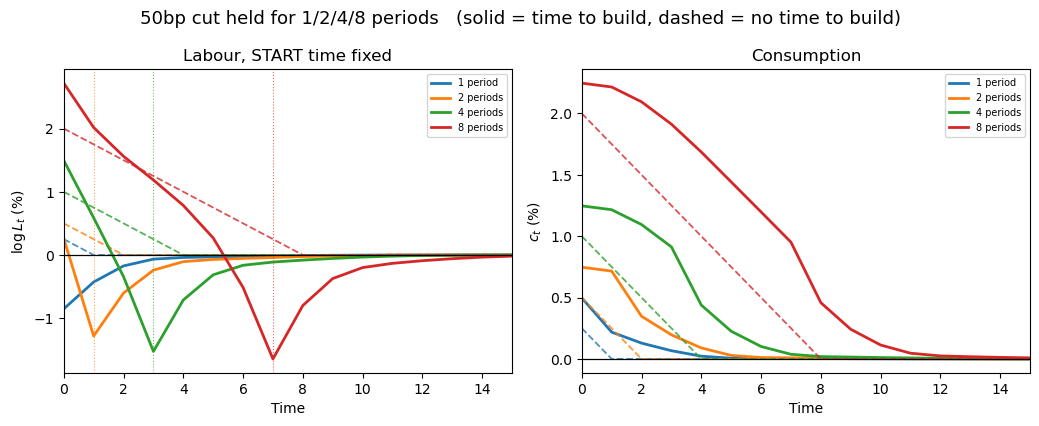

dotted verticals mark s = L - 1, the last period of the cut: the first cohort
whose window [s+1, s+tau] holds no cut date at all, and the trough of labour.

  cut length L   trough at s   trough (%)   labour at s=0 (%)
-------------------------------------------------------------
             1             0      -0.8532             -0.8532
             2             1      -1.2826              0.2600
             3             2      -1.4582              1.0158
             4             3      -1.5260              1.4959
             6             5      -1.6014              2.1612
             8             7      -1.6454              2.7192

50bp one-period cut, start-indexed labour by cohort tau (per cent of that
cohort's steady-state labour), start date s = 0:

     tau   firms   labour at s=0   labour at s=1
   ---------------------------------------------
       0       1         -1.9564         -1.9469
       1      31         -1.9469         -1.1529
       2      97         -

In [12]:
def labour_timing_figure(fname, bp=50, H=16):
    """Labour booked to the start of production, against the consumption it produces."""
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3))
    t = np.arange(H)
    for j, ln in enumerate([1, 2, 4, 8]):
        st = RES[(bp, ln, 'ttb')]; sn = RES[(bp, ln, 'ntb')]
        lbl = f'{ln} period' + ('s' if ln > 1 else '')
        axes[0].plot(t, 100 * st['lab'][:H], lw=2.0, color=f'C{j}', label=lbl)
        axes[0].plot(t, 100 * sn['lab'][:H], lw=1.3, ls='--', color=f'C{j}', alpha=0.8)
        axes[0].axvline(ln - 1, color=f'C{j}', lw=0.8, ls=':', alpha=0.7)
        axes[1].plot(t, 100 * st['c'][:H], lw=2.0, color=f'C{j}', label=lbl)
        axes[1].plot(t, 100 * sn['c'][:H], lw=1.3, ls='--', color=f'C{j}', alpha=0.8)
    for ax, ttl, yl in zip(axes, ['Labour, START time fixed', 'Consumption'],
                           [r'$\log L_t$ (%)', r'$c_t$ (%)']):
        ax.axhline(0, color='k', lw=0.9); ax.set_xlim(0, H - 1)
        ax.set_xlabel('Time'); ax.set_ylabel(yl); ax.set_title(ttl)
        ax.legend(fontsize=7)
    fig.suptitle(f'{bp}bp cut held for 1/2/4/8 periods   '
                 '(solid = time to build, dashed = no time to build)', fontsize=13)
    fig.tight_layout()
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    print(f'wrote {os.path.abspath(fname)}')
    plt.show(); plt.close(fig)
    print('dotted verticals mark s = L - 1, the last period of the cut: the first cohort')
    print('whose window [s+1, s+tau] holds no cut date at all, and the trough of labour.\n')
    print(f'{"cut length L":>14}{"trough at s":>14}{"trough (%)":>13}{"labour at s=0 (%)":>20}')
    print('-' * 61)
    for ln in LENGTHS:
        ss = RES[(bp, ln, 'ttb')]
        print(f'{ln:>14}{int(np.argmin(ss["lab"])):>14}{100*ss["lab"].min():>13.4f}'
              f'{100*ss["lab"][0]:>20.4f}')


labour_timing_figure('../semi_endo_rate_shock_labour_timing.png')

s50 = RES[(50, 1, 'ttb')]
print('\n50bp one-period cut, start-indexed labour by cohort tau (per cent of that')
print('cohort\'s steady-state labour), start date s = 0:\n')
nf = s50['n_firm']
nf0 = solve(np.array([rho]), tv=TVALS_TTB)['n_firm']
print(f'   {"tau":>5}{"firms":>8}{"labour at s=0":>16}{"labour at s=1":>16}')
print('   ' + '-' * 45)
for tt in np.unique(TVALS_TTB):
    m = TVALS_TTB == tt
    v = [100 * (nf[min(s + tt, T - 1), m].sum() / nf0[min(s + tt, T - 1), m].sum() - 1)
         for s in (0, 1)]
    print(f'   {tt:>5}{int(m.sum()):>8}{v[0]:>16.4f}{v[1]:>16.4f}')

## 5. The one specification choice that decides the answer

Everything above uses `euler_on='physical'`: the household's Euler equation applies to what
it actually consumes,

$$c_t = c_{t+1}-\tfrac1\gamma\big[i_t-\pi_{t+1}-r^n_t\big].$$

The lineage this model comes from (`new.ipynb`, `new_fixed.ipynb`, `demand_planner.ipynb`
and the `planner_*` notebooks) instead applies it to **measured** consumption $y=c+d$ and
then subtracts $d$. That writes $c=x+\varphi_{ya}a-d$, which applies
$\varphi_{ya}=(1+\eta)/(\gamma+\eta)=0.75$ to measured TFP but subtracts $d$ with
coefficient $1$, leaving a residual $-(1-\varphi_{ya})a$.

The consequence is stark, and it is the reason a rate cut appeared to do nothing: under
`'measured'` a purely discount-driven fall in the price level comes out **lowering**
physical consumption, even though it moves no physical quantity anywhere in the model.

$\varphi_{ya}$ is the elasticity of output to *productivity* — below one because labour
supply partially offsets a genuine productivity gain. A discount-driven price fall is not a
productivity gain and does not touch the marginal product of labour, so scaling it by
$\varphi_{ya}$ is a category error. The two specifications coincide exactly at $\gamma=1$,
where $\varphi_{ya}=1$, which is why the problem stayed hidden in the notebooks calibrated
there.

In [13]:
s_m = solve(path(50), euler_on='measured')
s_p = solve(path(50), euler_on='physical')
print('50bp one-period cut, consumption under each specification (per cent)\n')
print(f'   {"":<34}' + ''.join(f'{t:>9}' for t in range(9)))
print('   ' + '-' * 115)
print(f'   {"euler_on = measured (inherited)":<34}'
      + ''.join(f'{100*s_m["c"][t]:>9.4f}' for t in range(9)))
print(f'   {"euler_on = physical":<34}'
      + ''.join(f'{100*s_p["c"][t]:>9.4f}' for t in range(9)))
print(f'   {"difference (= d_t exactly)":<34}'
      + ''.join(f'{100*(s_p["c"]-s_m["c"])[t]:>9.4f}' for t in range(9)))
print(f'   {"discount content d_t":<34}'
      + ''.join(f'{100*s_m["d"][t]:>9.4f}' for t in range(9)))
print(f'\n   max |(c_phys - c_meas) - d| = {np.max(np.abs((s_p["c"]-s_m["c"]) - s_m["d"])):.2e}')
print('   -> the inherited specification subtracts exactly the price-level response,')
print('      which is exactly the transmission channel.\n')

acc = np.array([np.sum(s_p['pi'][t+1:]) / gamma for t in range(T)])
print('   and the physical path IS accumulated future inflation:')
print(f'   {"(1/gamma) * sum_{s>=t} pi_{s+1}":<34}'
      + ''.join(f'{100*acc[t]:>9.4f}' for t in range(9)))
print(f'   max |difference| over t >= 1 = {np.max(np.abs(acc[1:] - s_p["c"][1:])):.2e}')

50bp one-period cut, consumption under each specification (per cent)

                                             0        1        2        3        4        5        6        7        8
   -------------------------------------------------------------------------------------------------------------------
   euler_on = measured (inherited)      0.0027  -0.2185  -0.1288  -0.0670  -0.0224  -0.0060  -0.0052  -0.0037  -0.0037
   euler_on = physical                  0.4973   0.2185   0.1288   0.0670   0.0224   0.0060   0.0052   0.0037   0.0037
   difference (= d_t exactly)           0.4946   0.4369   0.2577   0.1339   0.0448   0.0120   0.0104   0.0074   0.0074
   discount content d_t                 0.4946   0.4369   0.2577   0.1339   0.0448   0.0120   0.0104   0.0074   0.0074

   max |(c_phys - c_meas) - d| = 0.00e+00
   -> the inherited specification subtracts exactly the price-level response,
      which is exactly the transmission channel.

   and the physical path IS accumulated futur

## 6. How big is the effect, and how long does it last?

In [14]:
print(f'{"cut":>8}{"length":>8}{"peak c":>10}{"at t":>6}{"half-life":>11}'
      f'{"periods c>0":>13}{"sum c":>10}{"lab trough":>12}{"sum lab":>10}{"sum c (no TTB)":>16}')
print('-' * 106)
for bp in (25, 50, 100):
    for ln in (1, 2, 4):
        ss = solve(path(bp, ln), euler_on='physical')
        sn = solve(path(bp, ln), euler_on='physical', tv=TVALS_NTB)
        cc = ss['c']; pk = cc.max(); j = int(np.argmax(cc))
        hl = int(np.argmax(cc < 0.5 * pk)) if pk > 0 else 0
        print(f'{bp:>6}bp{ln:>8}{100*pk:>9.4f}%{j:>6}{hl:>11}'
              f'{int(np.sum(cc > 1e-9)):>13}{100*np.sum(cc):>10.4f}'
              f'{100*ss["lab"].min():>12.4f}{100*np.sum(ss["lab"]):>10.4f}'
              f'{100*np.sum(sn["c"]):>16.4f}')
print('\n-> consumption is linear in the size of the cut and roughly linear in its length;')
print('   the decay is set by the tau distribution, not by the shock.  Labour is NOT')
print('   linear in the cut -- log L is a log of a sigma-power sum, so dispersion enters')
print('   at second order.  With no time to build cumulative c is just ln*bp/(1e4*gamma)')
print('   and labour never leaves consumption.')

     cut  length    peak c  at t  half-life  periods c>0     sum c  lab trough   sum lab  sum c (no TTB)
----------------------------------------------------------------------------------------------------------
    25bp       1   0.2485%     0          1           13    0.4779     -0.4256   -0.8217          0.1250
    25bp       2   0.3735%     0          2           14    1.0811     -0.6391   -1.0888          0.3750
    25bp       4   0.6235%     0          4           16    2.6632     -0.7592   -0.6317          1.2500
    50bp       1   0.4973%     0          1           13    0.9575     -0.8532   -1.6491          0.2500
    50bp       2   0.7473%     0          2           14    2.1667     -1.2826   -2.1913          0.7500
    50bp       4   1.2473%     0          4           16    5.3373     -1.5260   -1.2910          2.5000
   100bp       1   0.9959%     0          1           13    1.9222     -1.7149   -3.3213          0.5000
   100bp       2   1.4959%     0          2          

## 7. Cut, then hike above $\rho$

The experiment above is a pure cut. This one cuts for one period and then raises the rate
*above* $\rho$ for the next, which is the shape the planner actually chooses when it has to
offset a one-period demand shock.

The point of the hike is not to tighten in its own right. The cut leaves the price level
depressed and recovering for $\sim\tau$ periods, and that recovery keeps the real rate below
$\rho$ and consumption above steady state long after the cut is over. A subsequent hike
puts the price level back and cancels that tail. The model is linear, so the two impulse
responses simply add, and the size of the hike controls how much of the tail survives.

Note also that the hike moves consumption *before* it happens — the Euler equation is
forward-looking, so an anticipated hike at $t=1$ lowers consumption at $t=0$ as well.

In [15]:
def path_cut_hike(cut_bp, hike_bp, cut_len=1, hike_len=1):
    """Cut `cut_bp` below rho for `cut_len` periods, then `hike_bp` ABOVE rho, then rho."""
    return np.r_[np.full(cut_len, rho - cut_bp / 10000.0),
                 np.full(hike_len, rho + hike_bp / 10000.0),
                 np.full(25, rho)]


VARIANTS = [('50bp cut only',            path(50)),
            ('50bp cut, then +50bp',     path_cut_hike(50, 50)),
            ('50bp cut, then +100bp',    path_cut_hike(50, 100)),
            ('50bp cut, then +150bp',    path_cut_hike(50, 150))]

H = 10
print('CONSUMPTION c_t (%)\n')
print(f'   {"":<26}' + ''.join(f'{t:>9}' for t in range(H)))
print('   ' + '-' * 116)
for lab, rr in VARIANTS:
    ss = solve(rr, euler_on='physical')
    print(f'   {lab:<26}' + ''.join(f'{100*ss["c"][t]:>9.4f}' for t in range(H)))

print('\nEQUILIBRIUM LABOUR log L_t (%), start time held fixed\n')
print(f'   {"":<26}' + ''.join(f'{t:>9}' for t in range(H)))
print('   ' + '-' * 116)
for lab_, rr in VARIANTS:
    ss = solve(rr, euler_on='physical')
    print(f'   {lab_:<26}' + ''.join(f'{100*ss["lab"][t]:>9.4f}' for t in range(H)))

print(f'\n{"variant":<26}{"c_0":>10}{"c_1":>10}{"peak |c|":>11}{"periods |c|>1e-4":>19}'
      f'{"sum c (pp-per)":>16}')
print('-' * 92)
for lab, rr in VARIANTS:
    ss = solve(rr, euler_on='physical'); cc = ss['c']
    print(f'{lab:<26}{100*cc[0]:>10.4f}{100*cc[1]:>10.4f}{100*np.max(np.abs(cc)):>11.4f}'
          f'{int(np.sum(np.abs(cc) > 1e-6)):>19}{100*np.sum(cc):>16.4f}')
print('\n-> the hike cancels the tail; a large enough hike drives it negative.')
print('   `sum c` is the cumulative stimulus, and it is what the hike size controls.')

CONSUMPTION c_t (%)

                                     0        1        2        3        4        5        6        7        8        9
   --------------------------------------------------------------------------------------------------------------------
   50bp cut only                0.4973   0.2185   0.1288   0.0670   0.0224   0.0060   0.0052   0.0037   0.0037   0.0022
   50bp cut, then +50bp         0.2473  -0.2776  -0.0883  -0.0607  -0.0436  -0.0160  -0.0008  -0.0014   0.0000  -0.0015
   50bp cut, then +100bp       -0.0027  -0.7725  -0.3039  -0.1864  -0.1083  -0.0375  -0.0066  -0.0064  -0.0036  -0.0051
   50bp cut, then +150bp       -0.2527  -1.2661  -0.5179  -0.3104  -0.1718  -0.0585  -0.0123  -0.0113  -0.0071  -0.0086

EQUILIBRIUM LABOUR log L_t (%), start time held fixed

                                     0        1        2        3        4        5        6        7        8        9
   --------------------------------------------------------------------------------

wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_rate_shock_cut_then_hike.png


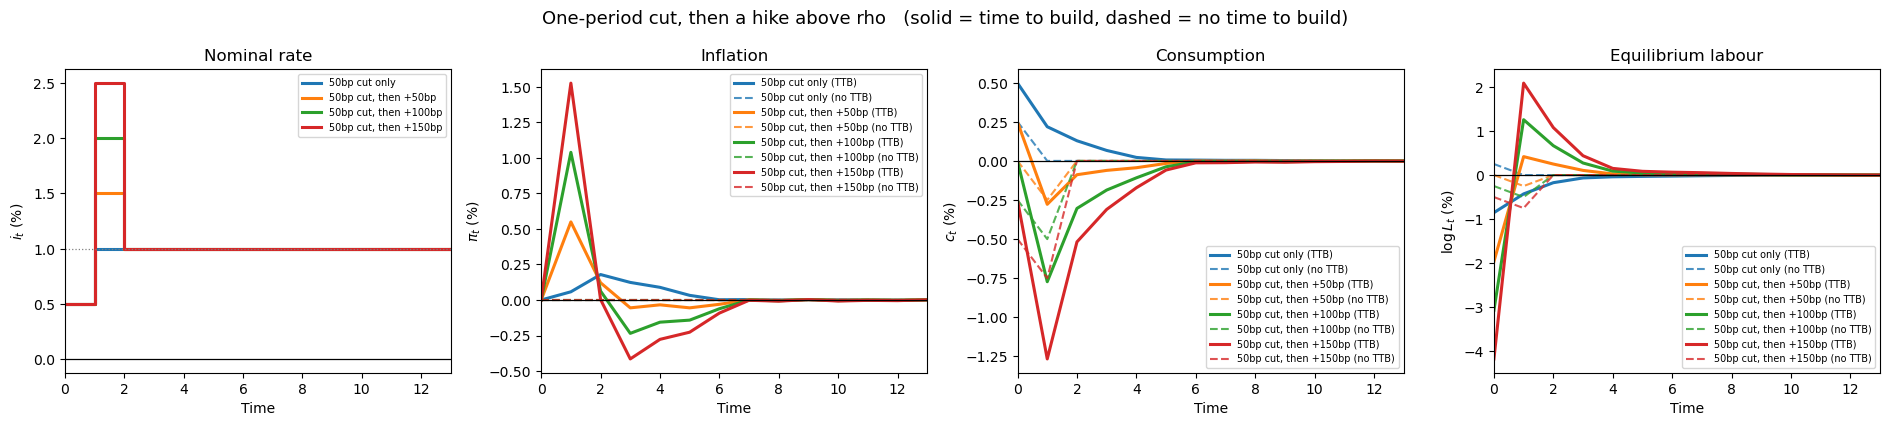

In [16]:
rate_figure([v[1] for v in VARIANTS], [v[0] for v in VARIANTS],
            '../semi_endo_rate_shock_cut_then_hike.png',
            'One-period cut, then a hike above rho')

## Summary

A rate cut in this model does move future output, the whole of that movement runs through
the firms' financing cost, and the sweep in section 4 puts a number on how much of it the
production lag is responsible for.

1. **Without time to build there is nothing to explain.** Set $\tau_i=0$ and no firm ever
   carries a financing cost: $\tilde A$ never moves, $\pi\equiv 0$, and the Euler equation
   delivers $c_t=(\rho-i_t)/\gamma$ while the cut is on and zero after. Labour equals
   consumption to machine precision, because with one $\tau$ cohort there is no
   relative-price dispersion for $\sum_i y_i/z_i$ to pick up. Cumulative consumption is
   exactly $\text{len}\times\text{bp}/(10^4\gamma)$ — the cut and nothing more.

2. **With time to build the same cut is still working $\max\tau_i=13$ periods later.** It
   sits inside the financing window of every firm delivering in $t,\dots,t+\tau_i$, their
   prices fall, and the unwinding of that is positive expected inflation, which holds the
   real rate below $\rho$ for the whole window. Cumulative consumption is 1.6x (8-period
   cut) to 3.8x (1-period cut) the no-time-to-build figure — the shorter the cut, the more
   of its work the lag is doing.

3. **Equilibrium labour, $L_s=\sum_i y_{i,s}/z_i$ with the start time held fixed, does not
   track consumption.** The hours are booked to the date production begins, so the batch
   delivered at $s+\tau_i$ is charged to $s$. A cohort starting at $s$ borrows over
   $[s+1,\,s+\tau_i]$, which overlaps a cut running on $[0,\,L-1]$ in
   $\min(L-1-s,\,\tau_i)$ dates: the overlap shrinks one date per period, so labour ramps
   down from its impact peak, and it hits zero exactly at $s=L-1$. That cohort — the one
   starting on the last period of the cut — is the first to get no cheap financing at all
   while still being priced against an aggregate its neighbours have cheapened, and it is
   the trough. Beyond $s=L-1$ the aggregate decompresses and labour returns to zero. The
   trough barely deepens with the length of the cut ($-0.85\%$ at $L=1$, $-1.65\%$ at
   $L=8$) while the impact peak grows with it, and cumulative labour only turns positive
   for cuts held 6 periods or longer.

4. **The specification choice in section 5 still decides the sign.** `euler_on='measured'`
   subtracts $d_t$, which is exactly the transmission channel, so the cut appears to *lower*
   future consumption. The difference between the two consumption paths equals $d_t$ to
   machine precision. `'physical'` is the default here; under it the consumption path is
   exactly $\tfrac1\gamma\sum_{s\ge t}\pi_{s+1}$.